# Where are the Medicaid gaps?

Each analog's launch curve (`launch_curves.csv`, Q0–Q20) has three kinds of quarter:
- **has Rx**: a TRx count
- **suppressed**: SDUD has a row but CMS hid the count (< 11 Rx). Kept blank, never 0.
- **no row**: no SDUD row at all for any of the analog's NDCs that quarter

Curves stop at the latest SDUD quarter, so recent launches simply have fewer quarters; that isn't a gap.

The enough-data rule drops an analog with any blank quarter after Q2. This notebook asks where those gaps cluster: small drugs, sc products, early quarters, or particular areas.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

ROOT = Path.cwd() if (Path.cwd() / "pipeline").exists() else Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
pd.set_option("display.max_rows", 100)

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical slots 1-2, validated for colorblind separation


def style(ax, title):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.tick_params(colors=INK2, labelsize=8.5, length=0)
    for s in ax.spines.values():
        s.set_visible(False)

In [2]:
c = pd.read_csv(PROCESSED / "launch_curves.csv")
f = pd.read_csv(PROCESSED / "analog_features.csv")

c["state"] = "has Rx"
c.loc[c.trx.isna() & c.suppressed_rows.notna(), "state"] = "suppressed"
c.loc[c.trx.isna() & c.suppressed_rows.isna(), "state"] = "no row"
c = c.merge(f[["analog_id", "route_group", "therapeutic_area", "peak_trx", "enough_data"]], on="analog_id")
c["area"] = c.therapeutic_area.str[:30].str.title().fillna("no ATC class")

print(f"{c.analog_id.nunique()} analogs with a launch curve, {len(c):,} analog-quarters")
c.state.value_counts().to_frame("quarters")

406 analogs with a launch curve, 6,966 analog-quarters


,quarters
state,
has Rx,6077
suppressed,685
no row,204


## By quarter since launch

Q0 is the launch quarter, often a partial quarter with only a few fills, so it's suppressed far more than any later quarter. The rule ignores Q0–Q2 for that reason.

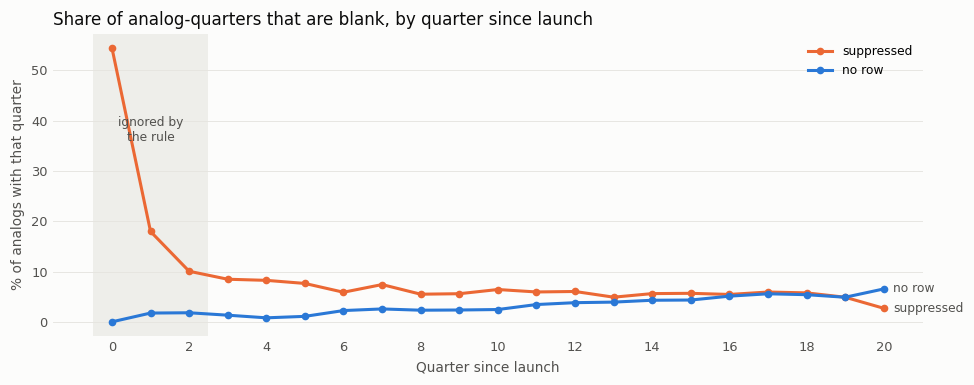

q_since_launch,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
state,,,,,,,,,,,,,,,,,,,,,
has Rx,45.6,80.3,88.1,90.2,91.0,91.3,91.9,90.0,92.2,92.1,...,90.6,90.2,91.2,90.1,90.0,89.5,88.5,88.8,90.2,90.8
no row,0.0,1.7,1.8,1.3,0.8,1.1,2.2,2.6,2.3,2.4,...,3.4,3.8,3.9,4.3,4.3,5.1,5.6,5.4,4.9,6.5
suppressed,54.4,18.0,10.1,8.5,8.2,7.6,5.9,7.4,5.5,5.6,...,5.9,6.0,4.9,5.6,5.7,5.4,5.9,5.8,4.9,2.7


In [3]:
by_q = pd.crosstab(c.q_since_launch, c.state, normalize="index").mul(100)

fig, ax = plt.subplots(figsize=(9, 3.6), dpi=110)
fig.patch.set_facecolor(SURFACE)
for state, color in [("suppressed", ORANGE), ("no row", BLUE)]:
    ax.plot(by_q.index, by_q[state], color=color, linewidth=2, marker="o", markersize=4, label=state)
    ax.annotate(state, (by_q.index[-1], by_q[state].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK2)
ax.axvspan(-0.5, 2.5, color=GRID, alpha=0.6, linewidth=0)
ax.text(1, by_q["suppressed"].max() * 0.75, "ignored by\nthe rule", ha="center", va="top", fontsize=8, color=INK2)
ax.set_xticks(range(0, 21, 2))
ax.set_xlabel("Quarter since launch", color=INK2, fontsize=9)
ax.set_ylabel("% of analogs with that quarter", color=INK2, fontsize=9)
ax.grid(axis="y", color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, loc="upper right")
style(ax, "Share of analog-quarters that are blank, by quarter since launch")
fig.tight_layout()
plt.show()

by_q.round(1).T

## Heatmap: every analog × quarter

One row per analog, sorted by peak TRx (largest at the top), oral and sc side by side. White = past the latest SDUD quarter.

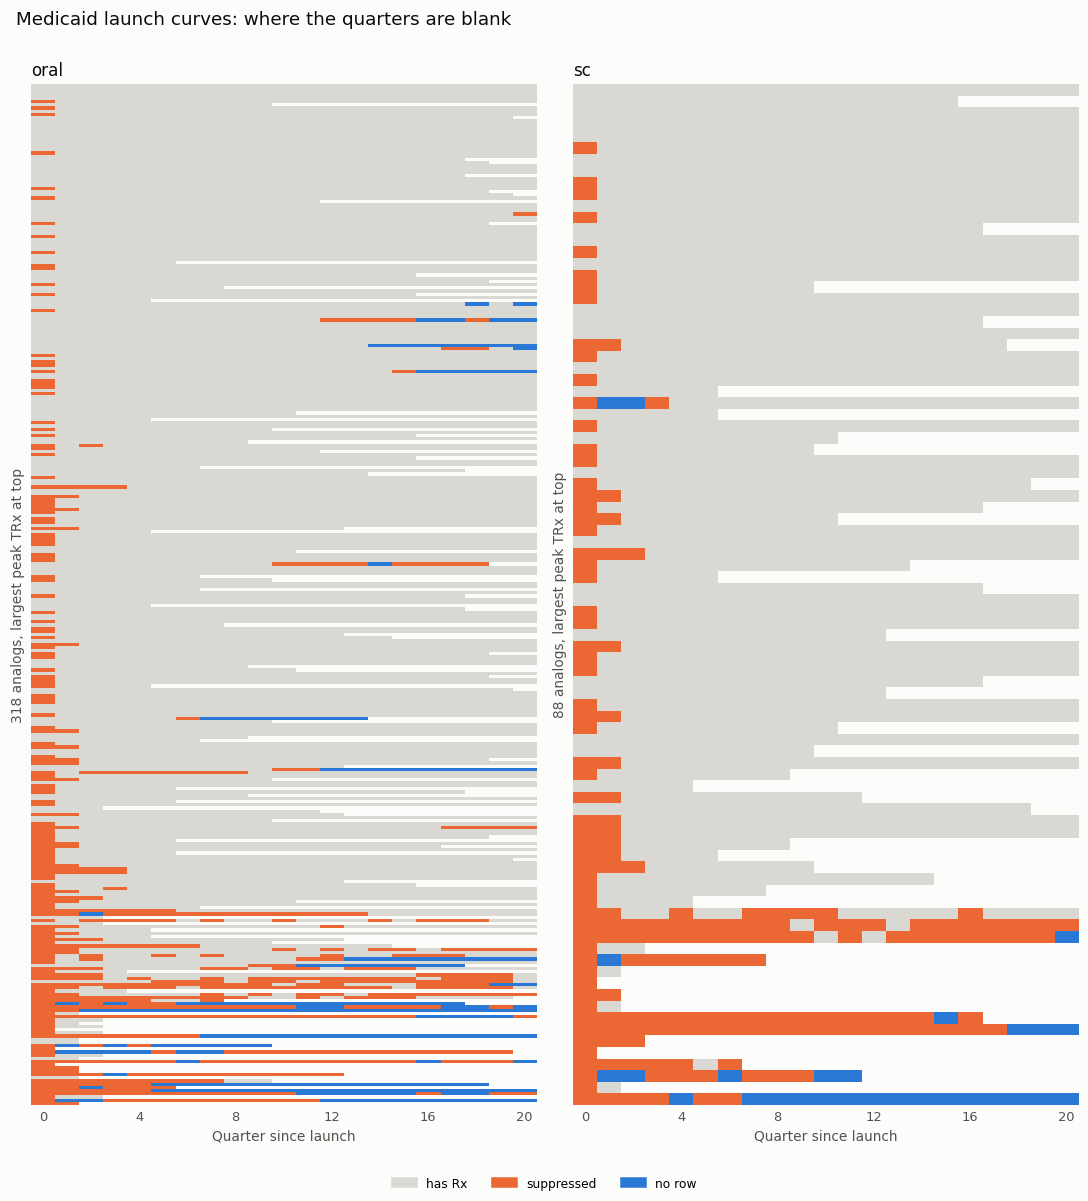

In [4]:
STATES = {"has Rx": 0, "suppressed": 1, "no row": 2}
cmap = ListedColormap(["#d9d8d3", ORANGE, BLUE])

fig, axes = plt.subplots(1, 2, figsize=(10, 11), dpi=110, gridspec_kw={"width_ratios": [1, 1]})
fig.patch.set_facecolor(SURFACE)
for ax, route in zip(axes, ["oral", "sc"]):
    d = c[c.route_group == route]
    order = d.groupby("analog_id").peak_trx.first().sort_values(ascending=False, na_position="last").index
    grid = d.pivot(index="analog_id", columns="q_since_launch", values="state").reindex(order)
    z = grid.apply(lambda col: col.map(STATES)).to_numpy(dtype=float)
    ax.imshow(np.ma.masked_invalid(z), aspect="auto", cmap=cmap, vmin=0, vmax=2, interpolation="none")
    ax.set_xticks(range(0, 21, 4))
    ax.set_yticks([])
    ax.set_xlabel("Quarter since launch", color=INK2, fontsize=9)
    ax.set_ylabel(f"{len(order)} analogs, largest peak TRx at top", color=INK2, fontsize=9)
    style(ax, route)
handles = [plt.Rectangle((0, 0), 1, 1, color=col) for col in ["#d9d8d3", ORANGE, BLUE]]
fig.legend(handles, list(STATES), ncol=3, loc="lower center", frameon=False, fontsize=8)
fig.suptitle("Medicaid launch curves: where the quarters are blank", x=0.02, ha="left", fontsize=12, color=INK)
fig.tight_layout(rect=(0, 0.03, 1, 0.98))
plt.show()

## Does size explain it?

Rule window = Q3–Q20. Analogs grouped by peak TRx (quintiles; analogs with no unsuppressed quarter outside the provisional ones have no peak).

In [5]:
w = c[c.q_since_launch >= 3]
per = w.groupby("analog_id").agg(
    route=("route_group", "first"), area=("area", "first"), peak_trx=("peak_trx", "first"),
    quarters=("state", "size"),
    suppressed=("state", lambda s: (s == "suppressed").sum()),
    no_row=("state", lambda s: (s == "no row").sum()),
)
per["blank"] = per.suppressed + per.no_row
per["any_blank"] = per.blank > 0
per["size"] = pd.qcut(per.peak_trx, 5, labels=["Q1 smallest", "Q2", "Q3", "Q4", "Q5 largest"])
per["size"] = per["size"].cat.add_categories("no peak").fillna("no peak")

size = per.groupby("size", observed=True).agg(
    analogs=("any_blank", "size"),
    peak_trx_range=("peak_trx", lambda s: f"{s.min():,.0f}–{s.max():,.0f}" if s.notna().any() else ""),
    pct_with_a_blank=("any_blank", lambda s: round(100 * s.mean())),
    pct_quarters_blank=("blank", "sum"),
)
size["pct_quarters_blank"] = (100 * size.pct_quarters_blank / per.groupby("size", observed=True).quarters.sum()).round(1)
size

,analogs,peak_trx_range,pct_with_a_blank,pct_quarters_blank
size,,,,
Q1 smallest,72,11–124,35,19.8
Q2,71,126–503,4,2.4
Q3,71,"505–1,509",3,0.9
Q4,71,"1,529–9,563",8,2.5
Q5 largest,72,"9,969–412,798",1,0.1
no peak,21,,100,99.0


## By route and by therapeutic area

In [6]:
def summary(by):
    g = per.groupby(by)
    return pd.DataFrame({
        "analogs": g.size(),
        "% with a blank Q3–Q20": (100 * g.any_blank.mean()).round(0),
        "% quarters suppressed": (100 * g.suppressed.sum() / g.quarters.sum()).round(1),
        "% quarters no row": (100 * g.no_row.sum() / g.quarters.sum()).round(1),
        "median peak TRx": g.peak_trx.median().round(0),
    })

summary("route")

,analogs,% with a blank Q3–Q20,% quarters suppressed,% quarters no row,median peak TRx
route,,,,,
oral,298,16.0,5.8,3.6,774.0
sc,80,12.0,7.4,2.0,905.0


In [7]:
summary("area").sort_values("% with a blank Q3–Q20", ascending=False)

,analogs,% with a blank Q3–Q20,% quarters suppressed,% quarters no row,median peak TRx
area,,,,,
"P Antiparasitic Products, Inse",5,80.0,47.2,28.1,635.0
J Antiinfectives For Systemic,31,35.0,7.9,5.5,3437.0
V Various,3,33.0,27.8,5.6,7154.0
D Dermatologicals,7,29.0,25.7,5.4,2996.0
G Genito Urinary System And Se,11,27.0,9.1,12.4,5955.0
M Musculo-Skeletal System,8,25.0,6.1,7.8,2461.0
C Cardiovascular System,18,17.0,8.0,1.1,1978.0
B Blood And Blood Forming Orga,22,14.0,2.7,7.2,803.0
L Antineoplastic And Immunomod,142,14.0,5.2,2.3,376.0


Route and area differences can just be size differences. Check the share with a blank within each size quintile:

In [8]:
pd.crosstab(per["size"], per.route, values=per.any_blank, aggfunc="mean").mul(100).round(0)

route,oral,sc
size,,
Q1 smallest,39.0,20.0
Q2,5.0,0.0
Q3,3.0,0.0
Q4,10.0,5.0
Q5 largest,2.0,0.0
no peak,100.0,100.0


## "No row" quarters: the curve stops

A quarter with no SDUD row at all usually means the drug stopped being dispensed (withdrawn or discontinued), or an NDC is missing from `ndc_map`. Analogs with the most no-row quarters:

In [9]:
nr = per[per.no_row > 0].sort_values("no_row", ascending=False)
first_nr = w[w.state == "no row"].groupby("analog_id").q_since_launch.min().rename("first no-row quarter")
nr.join(first_nr)[["route", "area", "peak_trx", "quarters", "suppressed", "no_row", "first no-row quarter"]].head(25)

,route,area,peak_trx,quarters,suppressed,no_row,first no-row quarter
analog_id,,,,,,,
bevyxxa_oral,oral,B Blood And Blood Forming Orga,NaN,18,0,18,3
ukoniq_oral,oral,L Antineoplastic And Immunomod,NaN,18,2,16,5
vyleesi_sc,sc,G Genito Urinary System And Se,NaN,18,3,15,4
impavido_oral,oral,"P Antiparasitic Products, Inse",NaN,18,4,14,7
truseltiq_oral,oral,L Antineoplastic And Immunomod,NaN,16,2,14,5
aemcolo_oral,oral,no ATC class,NaN,15,2,13,3
zurampic_oral,oral,M Musculo-Skeletal System,194.0,18,2,9,12
xenleta_oral,oral,J Antiinfectives For Systemic,NaN,18,9,9,12
addyi_oral,oral,G Genito Urinary System And Se,35.0,18,2,8,13


## Suppressed mid-curve: the small, steady drugs

Analogs with the most suppressed quarters in Q3–Q20 (blank because < 11 Rx, not because they stopped):

In [10]:
per[per.suppressed > 0].sort_values("suppressed", ascending=False)[
    ["route", "area", "peak_trx", "quarters", "suppressed", "no_row"]].head(25)

,route,area,peak_trx,quarters,suppressed,no_row
analog_id,,,,,,
signifor_sc,sc,H Systemic Hormonal Preparatio,16.0,18,16,0
tegsedi_sc,sc,N Nervous System,14.0,18,15,1
macrilen_oral,oral,V Various,NaN,18,15,3
kynamro_sc,sc,C Cardiovascular System,NaN,18,15,3
farydak_oral,oral,L Antineoplastic And Immunomod,17.0,18,15,0
daurismo_oral,oral,L Antineoplastic And Immunomod,NaN,18,14,4
lampit_oral,oral,"P Antiparasitic Products, Inse",NaN,17,13,4
kybella_sc,sc,D Dermatologicals,NaN,14,13,1
benznidazole_oral,oral,"P Antiparasitic Products, Inse",NaN,18,13,5


## Takeaways

- **Q0 is mostly suppressed (54%)**: the launch quarter is often a partial quarter with < 11 fills. The rule is right to ignore Q0–Q2. From Q3 on, 5–8% of quarters are suppressed, roughly flat.
- **"No row" grows with time (about 1% at Q3, 6.5% at Q20)**: drugs that stop being dispensed, e.g. Bevyxxa, Ukoniq, Zurampic (withdrawn) and the HCV orals (Viekira Pak, Olysio, Daklinza) once their market was cured.
- **Size is the main driver.** In the smallest fifth by peak TRx (11–124 per quarter), 35% of analogs have a blank quarter after Q2; in every other fifth it's 8% or less. 21 analogs never have an unsuppressed, non-provisional quarter.
- **Route isn't a driver**: oral 16% vs sc 12% with a blank, and within each size fifth sc is no worse than oral.
- **Areas differ mostly through size and short treatment courses**: antiparasitics and anti-infectives have the most gaps; nervous system has almost none.
- **Two different mechanisms behind one rule.** Small drugs are blank because of suppression (the value is 1–10, not missing); faded drugs are blank because use stopped. A rule that treats a suppressed quarter as "1–10 Rx" rather than missing, or that ends a curve at withdrawal, would keep more of the pool. Worth discussing before tightening anything.